In [1]:
%matplotlib widget
from matplotlib import pyplot as plt

from scipy.optimize import curve_fit
from scipy.signal import find_peaks
from scipy.signal import peak_widths
import numpy as np
import os
import importlib
from sklearn.metrics import mean_squared_error

os.chdir(r'C:\Users\nberr\ENS_Lyon\Thèse\Code\Pump_probe\Traces_treatment')
import P_and_P_func
importlib.reload(P_and_P_func)
from P_and_P_func import *


os.chdir(r'C:\Users\nberr\ENS_Lyon\Thèse\Code\Pump_probe\Traces_treatment')
import PaP_plotting_func
importlib.reload(PaP_plotting_func)
from PaP_plotting_func import *



fontsize=30
import matplotlib as mpl
mpl.rcParams["font.size"] = 18

In [ ]:
dir_root = r'H:\commun\Experiments (from 2018)\Nanoscope 2\Projects\ULTRASINGLE\Measurements\AuND_specific_AR_Marguet\Silice thick\AR 4,5\zone 2\D2'
dir_name = r'16-Oct-2026_PaP_Pp10uW_ldap410nm_ldas680nm'

dir_save_treated_data = dir_root + '\\' + dir_name + '_treated'


print('ok')
if not(os.path.exists(dir_save_treated_data)) :
        os.mkdir(dir_save_treated_data)

Data_set = P_and_P_dataset(dir_root, dir_name)

### Make a mean on all traces data

In [3]:
Data_set.synchronize_data()

### Find the time delay of the excitation

In [4]:
#Data_set.find_delay_zero(n_start=0, n_stop=-1, force_n=-1)
Data_set.find_delay_zero(n_start=0, n_stop=-1, force_n=-1)

61
-0.00028451490256980864
0.00028451490256980864


### Find the average signal before excitation

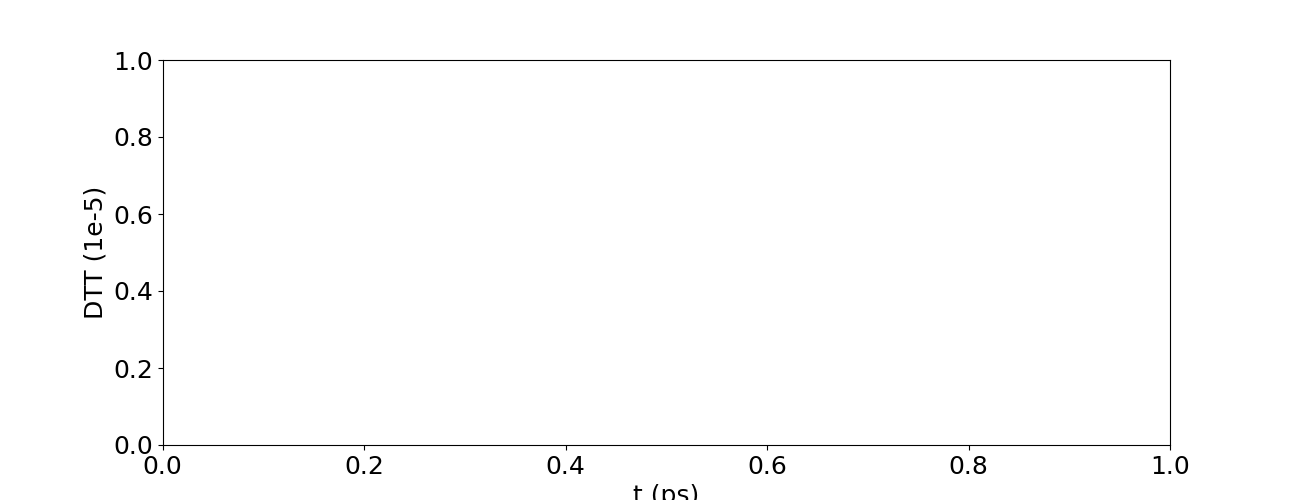

In [5]:
fig = Plot_all_traces_2(Data_set) 
#fig = Plot_all_traces(Data_set) 

In [6]:
idx_start = 2 #index to start the mean
idx_end = Data_set.t0_index - 3 #index to end the mean




mean_start = np.average(Data_set.DTT_tot[idx_start:idx_end])
Data_set.mean_start = mean_start
#Data_set.mean_start = 0



### For signals without electronic peak

# idx_start = 0 #index to start the mean
# idx_end = Data_set.t0_index - 0 #index to end the mean




In [7]:
print(mean_start)

0.00024201796635124308


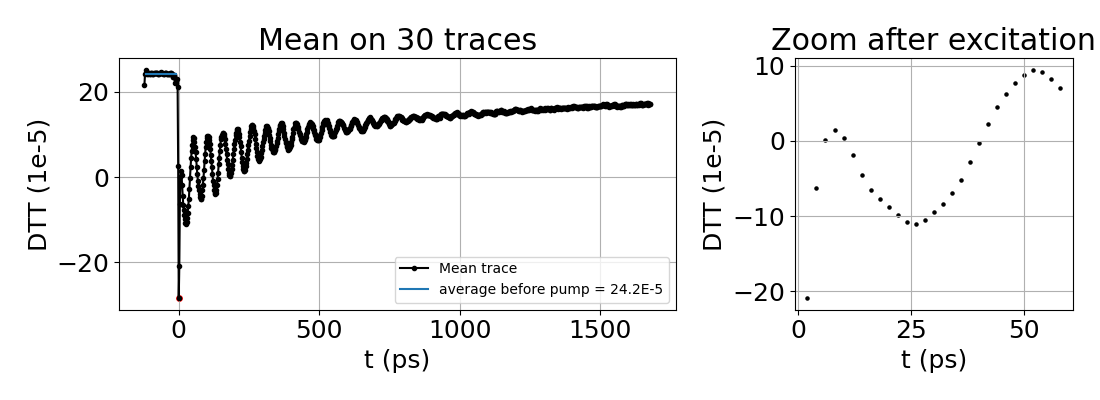

In [8]:
fig = Plot_mean_before_pulse(Data_set, idx_start, idx_end, mean_start) 


save_in_dir(fig, dir_save_treated_data, 'Mean_signal')

### Crop the delay to get the post-excitation signal

In [9]:
#Choose the starting index for the signal of interest
n_offset_start = 5

n_start = Data_set.t0_index + n_offset_start


Data_set.n_points_cropped = n_offset_start
Data_set.time_cropped = Data_set.t_step * Data_set.n_points_cropped
Data_set.crop_delay_and_remove_offset(n_start)

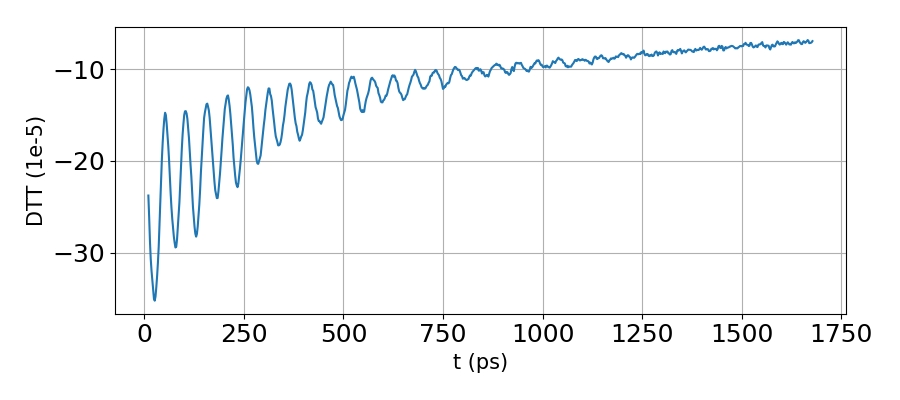

In [10]:
fig, ax = plt.subplots(figsize=(9, 4))
Plot_delay(Data_set, ax)
plt.tight_layout()

In [11]:
dir_save_treated_data = Data_set.dir_root + '\\' + Data_set.dir_name + r'_treated'
filename = 'Trace'

save_all_raw_signal(Data_set)
save_PaP_dataset(Data_set, dir_save_treated_data, filename)

In [12]:
print(Data_set.name)

H:\commun\Experiments (from 2018)\Nanoscope 2\Projects\ULTRASINGLE\Measurements\AuND_specific_AR_Marguet\Silice thick\AR 4,5\zone 2\D2\16-Oct-2026_PaP_Pp10uW_ldap410nm_ldas680nm
